# Surface water mapping with EDEA-EOKit

This notebook runs the full chain on a synthetic Sentinel-2 like scene: reading and scaling,
cloud masking, water index, area in hectares, threshold sensitivity, and the comparison of four
validation designs.

It uses no network access and no downloaded data. The scene is generated by
`make_demo_scene.py` (400 x 400 pixels, 10 m, EPSG:32631) and contains a river, a lake, a cloud
over the western edge of the lake, its shadow, and a saturated patch.

In [1]:
import os
import subprocess
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# make the package importable when the notebook is run from examples/
RACINE = os.path.abspath(os.path.join(os.getcwd(), ".."))
if os.path.basename(os.getcwd()) == "examples":
    sys.path.insert(0, RACINE)

SCENE = os.path.join(os.getcwd(), "_demo", "demo_s2.tif")
if not os.path.exists(SCENE):
    subprocess.run([sys.executable, "make_demo_scene.py"], check=True)

print("scene :", SCENE)

scene  : /nfs/110602094/temp/repo/edea-eokit/examples/_demo/demo_s2.tif  (400 x 400 px, 10 m)
points : /nfs/110602094/temp/repo/edea-eokit/examples/_demo/demo_points.gpkg  (500 points, 220 water)
water  : 7714 pixels, soit 77.1 ha de verite terrain
scene : /nfs/110602094/temp/repo/edea-eokit/examples/_demo/demo_s2.tif


## 1. Read the scene and check the scaling rule

The file stores reflectances as integers from 0 to 10 000 and carries an `scl` classification
band. The band names are given explicitly because this particular file has seven bands, an order
that the automatic Sentinel-2 table does not cover.

In [2]:
from eokit.io import read_scene

BANDES = ["blue", "green", "red", "nir", "swir1", "swir2", "scl"]
scene = read_scene(SCENE, sensor="sentinel2", band_names=BANDES)

print(scene)
print("scaling rule   :", scene.echelle.get("regle"))
print("masked bands   :", scene.bandes_masquees)
print("green median   :", round(float(np.nanmedian(scene.bands["green"])), 4))
print("scl values     :", np.unique(scene.bands["scl"]).astype(int))

Scene(sensor='sentinel2', shape=(400, 400), bands=['blue', 'green', 'red', 'nir', 'swir1', 'swir2', 'scl'])
scaling rule   : Sentinel-2 L2A (entiers 0-10000, facteur 1/10000)
masked bands   : ['scl']
green median   : 0.083
scl values     : [1 3 4 5 6 9]


Two things are visible above. The reflectances are now between 0 and 1, so the factor 1/10000 was
applied. The `scl` band kept its integer codes (1, 3, 4, 5, 6, 9): it was excluded from the scaling,
which is what makes the cloud mask usable.

## 2. Cloud mask

`cloud_mask()` returns `True` where the pixel is a cloud, a cloud shadow or a cirrus.

In [3]:
from eokit.cloud import cloud_mask

nuage = cloud_mask(scene)
print(f"masked pixels : {nuage.sum()} ({100 * nuage.mean():.1f} % of the scene)")

masked pixels : 9371 (5.9 % of the scene)


## 3. Water index and area

The MNDWI separates open water (positive) from soil and vegetation (negative). The area is
computed with the pixel size read from the transform, not with a hard-coded resolution.

In [4]:
from eokit.geometry import pixel_area_m2
from eokit.indices import compute

mndwi = compute("mndwi", scene.bands)
px_m2 = pixel_area_m2(scene)
print(f"pixel area : {px_m2:.1f} m2")

for seuil in (0.0, 0.1, 0.2, 0.3):
    eau = (mndwi > seuil) & ~nuage
    ha = eau.sum() * px_m2 / 10_000
    print(f"threshold {seuil:+.1f} -> {ha:7.1f} ha")

sans_masque = (mndwi > 0.1)
print()
print(f"without cloud mask : {sans_masque.sum() * px_m2 / 10_000:.1f} ha")
print(f"with cloud mask    : {((mndwi > 0.1) & ~nuage).sum() * px_m2 / 10_000:.1f} ha")

pixel area : 100.0 m2
threshold +0.0 ->    84.4 ha
threshold +0.1 ->    74.4 ha
threshold +0.2 ->    74.4 ha
threshold +0.3 ->    74.4 ha

without cloud mask : 74.9 ha
with cloud mask    : 74.4 ha


Skipping the mask changes little at a threshold of 0.1 (74.9 ha against 74.4), because the cloud is
only slightly positive in MNDWI on this scene. At a threshold of 0.0 the gap reaches ten hectares,
and the cloud alone would be counted as water. The mask therefore matters most for the pixels whose
index sits close to zero, which is exactly where the threshold is debated. Above 0.1 the estimate is
stable, because the two classes are well separated here.

A quick look at the index and at the mask:

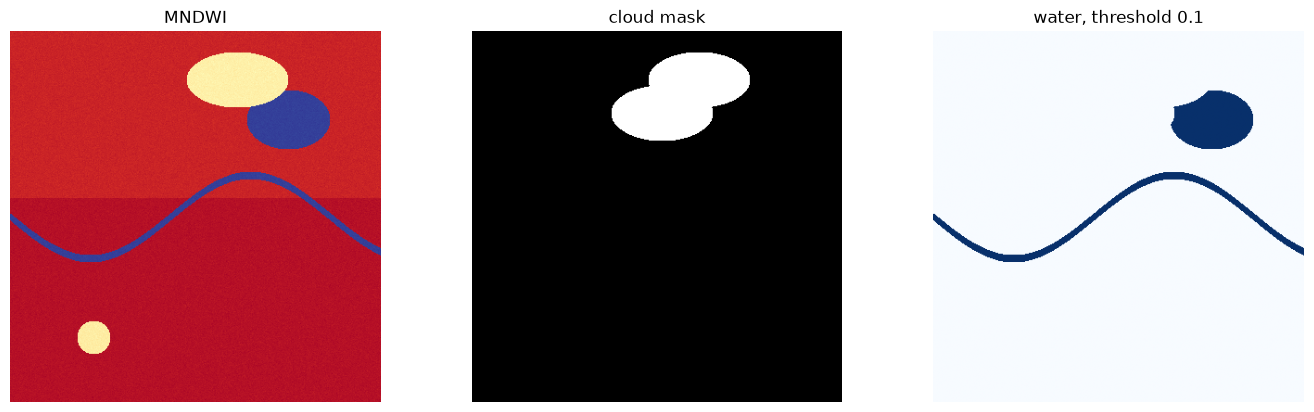

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
axes[0].imshow(np.clip(mndwi, -0.8, 0.8), cmap="RdYlBu")
axes[0].set_title("MNDWI")
axes[1].imshow(nuage, cmap="gray")
axes[1].set_title("cloud mask")
axes[2].imshow((mndwi > 0.1) & ~nuage, cmap="Blues")
axes[2].set_title("water, threshold 0.1")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 4. The ground size of a pixel

The same scene stored in EPSG:4326 no longer has a pixel step in metres. `pixel_area_m2()` then
computes the local metre size at the latitude of the scene, which explains why a nominal 10 m
resolution turns into a slightly different area.

In [6]:
import rasterio
from rasterio.warp import Resampling, calculate_default_transform, reproject

CHEMIN_4326 = os.path.join(os.getcwd(), "_demo", "demo_s2_4326.tif")
with rasterio.open(SCENE) as src:
    transform, width, height = calculate_default_transform(
        src.crs, "EPSG:4326", src.width, src.height, *src.bounds)
    profil = src.profile.copy()
    profil.update(crs="EPSG:4326", transform=transform, width=width, height=height)
    with rasterio.open(CHEMIN_4326, "w", **profil) as dst:
        for i in range(1, src.count + 1):
            reproject(source=rasterio.band(src, i), destination=rasterio.band(dst, i),
                      src_transform=src.transform, src_crs=src.crs,
                      dst_transform=transform, dst_crs="EPSG:4326",
                      resampling=Resampling.nearest)
        for i, nom in enumerate(BANDES, start=1):
            dst.set_band_description(i, nom)

g = read_scene(CHEMIN_4326, sensor="sentinel2", band_names=BANDES)
print("pixel step (degrees) :", round(abs(g.transform.a), 6), "x", round(abs(g.transform.e), 6))
print(f"pixel area in metres : {pixel_area_m2(g):.1f} m2  (nominal 100.0 m2)")
print(f"same water surface    : {((compute('mndwi', g.bands) > 0.1)).sum() * pixel_area_m2(g) / 10_000:.1f} ha")

pixel step (degrees) : 9e-05 x 9e-05
pixel area in metres : 100.1 m2  (nominal 100.0 m2)
same water surface    : 75.0 ha


The step reads `0.000090` degree, which a two-decimal interface displays as `0.00 m`. The area of a
pixel is nevertheless close to 100 m2 at this latitude, and it drifts towards 96 m2 at the latitude
of Niamey. Hard-coding the nominal resolution is right here and wrong elsewhere.

## 5. Validation designs

Five hundred reference points were sampled from the scene, 220 in water and 280 on land. The same
Random Forest and the same features are used in every design; only the train and test split changes.

In [7]:
import geopandas as gpd

from eokit.validation_spatiale import comparer_strategies

points = gpd.read_file(os.path.join(os.getcwd(), "_demo", "demo_points.gpkg"))
print(points.head(3))
print(points["classe"].value_counts())

   id classe               geometry
0   1    eau  POINT (452965 753045)
1   2    eau  POINT (452855 753225)
2   3    eau  POINT (452315 752385)
classe
autre    280
eau      220
Name: count, dtype: int64


In [8]:
tableau = comparer_strategies(scene, points, "classe",
                             noms_indices=("ndvi", "mndwi"),
                             k_folds=5, buffer_m=100.0, taille_bloc=500.0)
colonnes = ["OA", "Kappa", "Dist_min_m", "Moran_I_residus", "Moran_p", "Biais_OA"]
tableau[colonnes].round(3)

[eokit] Echantillons retenus : 500 | variables : 9 (blue, green, red, nir, swir1, swir2, scl, ndvi, mndwi)


[eokit] Evaluation : Aleatoire k-fold ...


[eokit] Evaluation : Buffer d'exclusion (100 m) ...


[eokit] Evaluation : Hold-out spatial (KMeans) ...


[eokit] Evaluation : Spatial block CV (500 m) ...


,OA,Kappa,Dist_min_m,Moran_I_residus,Moran_p,Biais_OA
Aleatoire k-fold,98.8,0.976,60.4,0.261,0.002,0.8
Buffer d'exclusion (100 m),97.6,0.951,156.0,0.527,0.002,-0.4
Hold-out spatial (KMeans),98.0,0.959,604.4,0.575,0.002,0.0
Spatial block CV (500 m),98.0,0.959,190.5,0.575,0.002,0.0


How to read this table on a synthetic scene:

- the two classes are spectrally distinct here, so all four designs land within one accuracy point,
  and the optimistic bias stays below one point. The published case study reports the divergence
  observed on real multi-date data, where the same function separates the designs by tens of points;
- the median distance between training and test points is the quantity that explains the gap when
  there is one: a random split leaves neighbours a few metres apart, a block split pushes them
  hundreds of metres away;
- Moran's I of the residuals is positive and its permutation p-value is below 0.01, which is the
  signature of spatial structure that a random split cannot see.

## 6. What to remember

1. The scaling rule is deduced, stored in `scene.echelle`, and never applied to classification bands.
2. The area of a pixel comes from the transform, and stays correct when the CRS is in degrees.
3. The cloud mask removes more surface than the water itself on a scene like this one.
4. The validation design, not the classifier, decides part of the reported accuracy, and the gap
   between designs is measurable.